# Error analysis

Why does a trained model fail on a maze? For every failed test maze, each wrong passage pixel
is put in one of four categories:

| category | meaning | colour |
|---|---|---|
| `missed_forced` | a pixel that **every** shortest path uses is not marked: the path has a gap | red |
| `missed_tied` | a pixel of one of several equally short routes is not marked | orange |
| `extra_route` | a marked pixel on a start–exit route that is not shortest (around a loop) | magenta |
| `extra_deadend` | a marked pixel in a dead end (removed by dead-end filling) | cyan |

Also reported per setting: how many failed predictions still connect start and exit, and how
many are exactly one shortest path (`dataset.is_shortest_path`; such answers are correct but
count as failed, because the target marks all tied routes).

Needs the checkpoints in `checkpoints/<run>.pt` and `results/<run>/config.json` written by
`experiments.ipynb` or `scripts/experiment.py`. Results are saved to
`results/<run>/error_analysis.json` and `error_analysis.png`.

## Setup

In [1]:
import json
import subprocess
import sys
from pathlib import Path
from types import SimpleNamespace

REPO_URL = "https://github.com/yoshi0428/maze-generalization.git"
BRANCH = "main"

if "google.colab" in sys.modules:
    root = Path("/content/maze-generalization")
    if root.is_dir():
        subprocess.run(["git", "-C", str(root), "pull", "--ff-only"], check=True)
    else:
        subprocess.run(["git", "clone", "-b", BRANCH, REPO_URL, str(root)], check=True)
else:
    root = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent

sys.path.insert(0, str(root / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm

from dataset import bfs_distances, is_shortest_path, make_test_datasets
from runner import MODELS

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cuda


In [2]:
RUNS = ["dtnet_s15_loops", "dtnet_s15_noloops"]  # results/<run>/ and checkpoints/<run>.pt
ITERS = 300                    # test-time iterations (ignored by the feedforward baseline)
SIZES = {15: 200, 31: 200, 63: 100}  # size -> number of test mazes
TEST_WR = (0.0, 0.1)           # fraction of walls removed in the test mazes
EXAMPLE_WR, EXAMPLE_SIZE, N_EXAMPLES = 0.1, 31, 3  # failed mazes to plot per run
BATCH = 50

## Helpers

In [3]:
CATEGORIES = ("missed_forced", "missed_tied", "extra_route", "extra_deadend")


def load_run(name):
    """Model, prediction function and config of a finished run."""
    cfg = SimpleNamespace(**json.loads((root / "results" / name / "config.json").read_text()))
    module, make_model = MODELS[cfg.model]
    model = make_model(cfg).to(device)
    model.load_state_dict(torch.load(root / "checkpoints" / f"{name}.pt", map_location=device))
    return model, module.predict, cfg


def route_region(open_, start, goal):
    """Pixels on some start-exit route: what is left after repeatedly filling dead ends."""
    keep = open_.copy()
    while True:
        p = np.pad(keep, 1)
        neighbours = p[:-2, 1:-1].astype(int) + p[2:, 1:-1] + p[1:-1, :-2] + p[1:-1, 2:]
        dead = keep & (neighbours <= 1)
        dead[start] = dead[goal] = False
        if not dead.any():
            return keep
        keep &= ~dead


def analyse(x, pred):
    """Error pixels per category, plus masks for plotting, for one maze (numpy x, bool pred)."""
    open_ = x[0] > 0.5
    start, goal = (tuple(np.argwhere(x[c] > 0.5)[0]) for c in (1, 2))
    from_start, from_goal = bfs_distances(open_, start), bfs_distances(open_, goal)
    length = from_start[goal]
    target = (from_start >= 0) & (from_goal >= 0) & (from_start + from_goal == length)
    # Forced = the only target pixel at its distance from the start.
    per_level = np.bincount(from_start[target], minlength=from_start.max() + 1)
    forced = target & (per_level[np.maximum(from_start, 0)] == 1)
    routes = route_region(open_, start, goal)
    extra = pred & ~target
    counts = {
        "missed_forced": int((forced & ~pred).sum()),
        "missed_tied": int((target & ~forced & ~pred).sum()),
        "extra_route": int((extra & routes).sum()),
        "extra_deadend": int((extra & ~routes).sum()),
    }
    info = {
        "connected": bool(bfs_distances(pred & open_, start)[goal] >= 0),
        "one_shortest_path": is_shortest_path(x[0].astype(np.uint8), start, goal, pred),
    }
    return counts, info, (target, forced, routes)


def render_errors(x, pred, masks):
    target, forced, routes = masks
    img = np.repeat(x[0][..., None], 3, -1) * 0.85
    img[pred & target] = (0.2, 0.7, 0.2)
    img[forced & ~pred] = (0.9, 0.1, 0.1)
    img[target & ~forced & ~pred] = (1.0, 0.6, 0.1)
    img[pred & ~target & routes] = (0.8, 0.2, 0.8)
    img[pred & ~target & ~routes] = (0.1, 0.8, 0.9)
    img[x[1] > 0.5] = (0.0, 0.0, 1.0)
    img[x[2] > 0.5] = (0.0, 0.0, 0.4)
    return img

## Run the analysis

Test mazes come from the run's test generators with the same seed as the run's own test sets.
Takes a few minutes per run.

In [ ]:
rows, examples = [], {}
for name in tqdm(RUNS, desc="runs"):

    model, predict, cfg = load_run(name)
    summary, examples[name] = {}, []

    for wr in TEST_WR:
        for size, n in SIZES.items():

            ds = make_test_datasets(list(cfg.test_generators), size, n, list(cfg.train_generators),
                                    seed=cfg.seed + 1, wall_removal=wr)[size]

            X = torch.stack([ds[i][0] for i in range(n)])

            preds = []
            for b in range(0, n, BATCH):
                with torch.autocast(device, dtype=torch.bfloat16, enabled=device == "cuda"):
                    preds.append(predict(model, X[b:b + BATCH].to(device), ITERS).cpu())

            P, Xn = torch.cat(preds)[:, 0].numpy() > 0.5, X.numpy()

            row = {"run": name, "wall removal": wr, "size": size, "n": n, "failed": 0,
                   "connected": 0, "one_shortest_path": 0,
                   **{f"mazes {c}": 0 for c in CATEGORIES}, **{c: 0 for c in CATEGORIES}}

            for i in range(n):
                counts, info, masks = analyse(Xn[i], P[i])
                
                if not any(counts.values()):
                    continue

                row["failed"] += 1
                row["connected"] += info["connected"]
                row["one_shortest_path"] += info["one_shortest_path"]
                
                for c, v in counts.items():
                    row[c] += v
                    row[f"mazes {c}"] += v > 0
                
                if (wr, size) == (EXAMPLE_WR, EXAMPLE_SIZE) and len(examples[name]) < N_EXAMPLES:
                    examples[name].append((Xn[i], P[i], masks, counts))
            
            rows.append(row)
            summary[f"{wr}/{size}"] = {k: v for k, v in row.items() if k not in ("run", "wall removal", "size")}

    (root / "results" / name / "error_analysis.json").write_text(json.dumps(summary, indent=1, default=int))

    del model

    if device == "cuda":
        torch.cuda.empty_cache()

df = pd.DataFrame(rows).set_index(["run", "wall removal", "size"])

runs: 100%|██████████| 2/2 [01:10<00:00, 35.11s/it]


## Results

Failed mazes, and how many of them still connect start and exit or are exactly one shortest
path:

In [5]:
counts = df[["n", "failed", "connected", "one_shortest_path"]]
counts

n  failed  connected  one_shortest_path
run               wall removal size                                           
dtnet_s15_loops   0.0          15    200       0          0                  0
                               31    200      52          6                  0
                               63    100      77          0                  0
                  0.1          15    200      26         26                  7
                               31    200      75         26                  8
                               63    100      82         12                  4
dtnet_s15_noloops 0.0          15    200       0          0                  0
                               31    200       0          0                  0
                               63    100       0          0                  0
                  0.1          15    200     200        197                  0
                               31    200     200        198                  0
                               63    100     100         98                  0

Share of the wrong pixels in each category (rows with no failures are empty):

In [6]:
shares = df[list(CATEGORIES)].div(df[list(CATEGORIES)].sum(axis=1), axis=0)
shares.style.format("{:.0%}", na_rep="–").background_gradient(cmap="Reds", vmin=0, vmax=1, axis=None)

Number of failed mazes with at least one wrong pixel of each category:

In [7]:
df[[f"mazes {c}" for c in CATEGORIES]]

mazes missed_forced  mazes missed_tied  \
run               wall removal size                                           
dtnet_s15_loops   0.0          15                      0                  0   
                               31                     46                  0   
                               63                     77                  0   
                  0.1          15                      1                 17   
                               31                     49                 57   
                               63                     68                 69   
dtnet_s15_noloops 0.0          15                      0                  0   
                               31                      0                  0   
                               63                      0                  0   
                  0.1          15                     13                  9   
                               31                     23                 27   
                               63                     19                 23   

                                     mazes extra_route  mazes extra_deadend  
run               wall removal size                                          
dtnet_s15_loops   0.0          15                    0                    0  
                               31                    0                   41  
                               63                    0                   69  
                  0.1          15                   10                    0  
                               31                   54                    4  
                               63                   73                    0  
dtnet_s15_noloops 0.0          15                    0                    0  
                               31                    0                    0  
                               63                    0                    0  
                  0.1          15                  200                    0  
                               31                  200                    0  
                               63                  100                    0

## Examples

The first failed mazes at the example setting. Green = correct, red = missed (forced),
orange = missed (tied route), magenta = extra on a longer route, cyan = extra in a dead end;
blue = start, dark blue = exit.

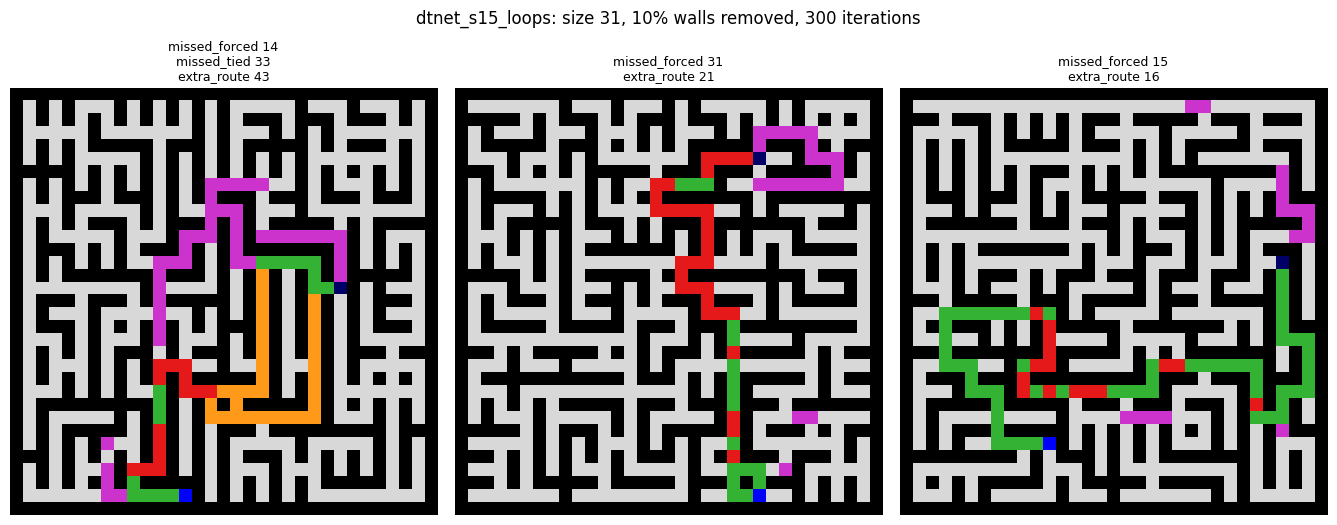

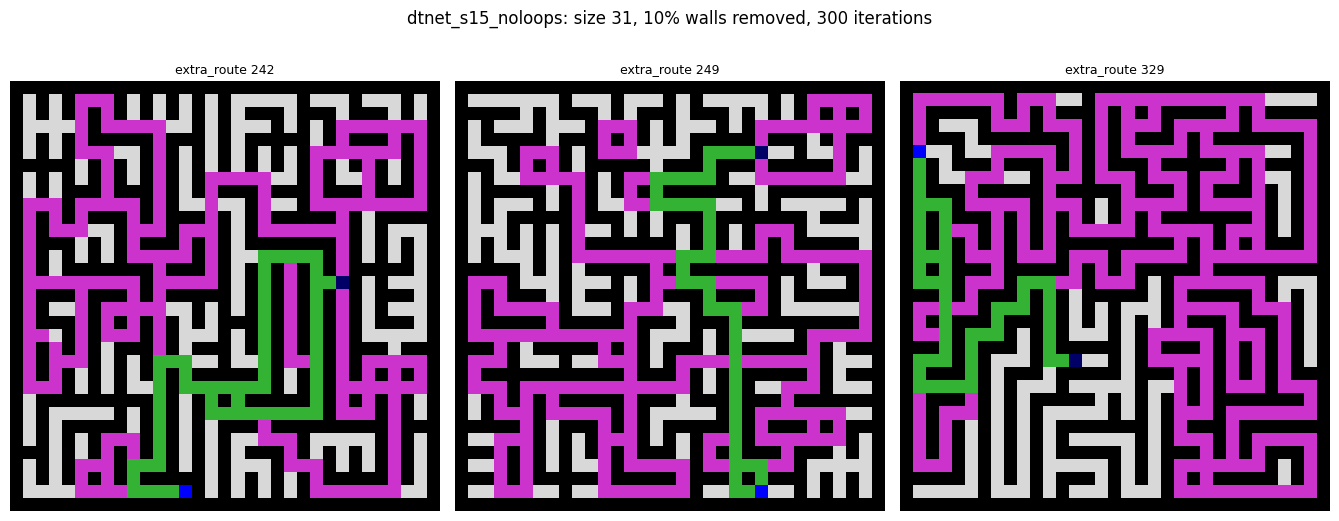

In [8]:
for name, items in examples.items():
    if not items:
        print(f"{name}: no failures at wall removal {EXAMPLE_WR}, size {EXAMPLE_SIZE}")
        continue
    fig, axes = plt.subplots(1, N_EXAMPLES, figsize=(4.5 * N_EXAMPLES, 5), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, (x, pred, masks, counts) in zip(axes.flat, items):
        ax.imshow(render_errors(x, pred, masks))
        ax.set_title("\n".join(f"{c} {v}" for c, v in counts.items() if v), fontsize=9)
    fig.suptitle(f"{name}: size {EXAMPLE_SIZE}, {EXAMPLE_WR:.0%} walls removed, {ITERS} iterations", y=1.04)
    fig.tight_layout()
    fig.savefig(root / "results" / name / "error_analysis.png", dpi=110, bbox_inches="tight")
    plt.show()